In [1]:
import pandas as pd
import numpy as np
import re
import pyreadstat

In [2]:
belief_col = ['Belief_opinion_on_the_extent_to_which_this_individual_feels_it_is_justified_for_people_to_use_violence_to_pursue_their_political_goals_in_this_country_Symbol','Belief_opinion_on_the_number_of_immigrants_in_america_Symbol']

In [3]:
anes2024 = pd.read_csv('../../original_data/anes_timeseries_2024_csv_20250808/anes_timeseries_2024_csv_20250808.csv')
anes2024

C:\Users\yuyue\AppData\Local\Temp\ipykernel_38244\3777620387.py:1: DtypeWarning: Columns (8,10,11,16,18,19,20,22,23,24,26,27,28,30,31,36,38,39,1448,1449,1450,1451,1452,1455,1456,1457,1458,1459,1463,1464,1465) have mixed types. Specify dtype option on import or set low_memory=False.
  anes2024 = pd.read_csv('../../original_data/anes_timeseries_2024_csv_20250808/anes_timeseries_2024_csv_20250808.csv')


,version,V240001,V200001,V160001_orig,V240002a,V240002b,V240002c,V240003,V240101a,V240101b,...,V245009,V245010,V245011,V245012,V245013,V245014,V245015,V245016,V245017,V245018
0,ANES2024TimeSeries_20250808,140001,200015,401318,2,2,2,1,,,...,-1,-1. Inapplicable,-1,-1,-1,-1,-1,-1,-1,-1
1,ANES2024TimeSeries_20250808,140002,200022,300261,2,2,2,1,,,...,-1,-1. Inapplicable,-1,-1,-1,-1,-1,-1,-1,-1
2,ANES2024TimeSeries_20250808,140003,200039,400181,2,2,2,1,,,...,-1,-1. Inapplicable,-1,-1,-1,-1,-1,-1,-1,-1
3,ANES2024TimeSeries_20250808,140004,200046,300171,2,2,2,1,,,...,-1,-1. Inapplicable,-1,-1,-1,-1,-1,-1,-1,-1
4,ANES2024TimeSeries_20250808,140005,200053,405145,2,2,2,1,,,...,-1,-1. Inapplicable,-1,-1,-1,-1,-1,-1,-1,-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5516,ANES2024TimeSeries_20250808,399764,-1,-1,1,-6,1,3,0.117236,,...,0,-1. Inapplicable,-1,-1,-1,-1,-1,-1,-1,-1
5517,ANES2024TimeSeries_20250808,399815,-1,-1,1,5,2,3,1.501748,1.15260127111406,...,1,IWER76,1960,3,0,1,5,0,1,0
5518,ANES2024TimeSeries_20250808,399830,-1,-1,1,-6,1,3,1.114477,,...,2,-1. Inapplicable,-1,-1,-1,-1,-1,-1,-1,-1
5519,ANES2024TimeSeries_20250808,399841,-1,-1,4,4,2,3,1.179447,1.1924221171493,...,2,IWER75,1950,3,0,1,5,0,1,2


In [4]:
cces2024 = pd.read_csv('../../original_data/CCES_2024/CCES24_Common_OUTPUT_vv_topost_final.csv')
cces2024

,caseid,tookpost,commonweight,commonpostweight,vvweight,vvweight_post,CCEStake,add_confirm,inputzip,birthyr,...,starttime_post,endtime_post,TS_g2024,TS_voterstatus,TS_p2024,TS_p2024_party,TS_pp2024,TS_pp2024_party,TS_state,TS_partyreg
0,1853651564,2,0.418897,0.180057,1.407497,0.822485,1,1.0,NaN,1978,...,2024-11-09 03:00:05,2024-11-09 03:09:39,3.0,1.0,7.0,NaN,7.0,NaN,PA,2.0
1,1853655732,2,0.946650,0.700897,0.470183,0.435126,1,NaN,11236.0,1968,...,2024-11-10 22:46:35,2024-11-10 22:56:59,2.0,1.0,7.0,NaN,7.0,NaN,NY,8.0
2,1852716424,2,0.194303,0.046275,0.245400,0.172787,1,1.0,NaN,1946,...,2024-11-11 03:52:52,2024-11-11 04:11:38,3.0,1.0,7.0,NaN,7.0,NaN,PA,NaN
3,1853644254,2,0.083223,0.008897,0.465415,0.636743,1,NaN,90039.0,2001,...,2024-12-08 03:31:26,2024-12-08 04:30:16,1.0,1.0,7.0,NaN,7.0,NaN,CA,NaN
4,1853644132,2,0.596598,0.555395,1.676258,1.609462,1,1.0,NaN,1955,...,2024-11-06 23:47:48,2024-11-07 00:27:52,1.0,1.0,1.0,NaN,7.0,NaN,MT,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,1906098636,2,0.255305,2.469711,2.747473,2.730659,1,1.0,NaN,1950,...,2024-11-11 03:23:14,2024-11-11 03:42:51,4.0,1.0,4.0,6.0,7.0,NaN,ID,8.0
59996,1904587154,2,0.964466,0.931537,0.752686,0.654171,1,1.0,NaN,1981,...,2024-12-06 01:06:11,2024-12-06 01:20:46,6.0,1.0,6.0,1.0,7.0,NaN,IL,NaN
59997,1906111230,2,0.246773,0.195502,0.261751,0.619091,1,NaN,89118.0,1955,...,2024-12-02 00:08:50,2024-12-02 00:31:20,3.0,1.0,3.0,NaN,7.0,NaN,NV,2.0
59998,1906096834,2,3.177289,8.421328,6.707039,8.972966,1,1.0,NaN,2000,...,2024-11-09 14:06:22,2024-11-09 14:19:11,4.0,1.0,7.0,NaN,7.0,NaN,NJ,2.0


In [5]:
cces2024['gender4'].value_counts()

gender4
2    31992
1    27454
3      448
4      106
Name: count, dtype: int64

In [6]:
cces2024.columns.to_list()

['caseid',
 'tookpost',
 'commonweight',
 'commonpostweight',
 'vvweight',
 'vvweight_post',
 'CCEStake',
 'add_confirm',
 'inputzip',
 'birthyr',
 'gender4',
 'gender4_t',
 'educ',
 'race',
 'race_other',
 'hispanic',
 'multrace_1',
 'multrace_2',
 'multrace_3',
 'multrace_4',
 'multrace_5',
 'multrace_8',
 'multrace_97',
 'multrace_98',
 'comptype',
 'votereg',
 'votereg_f',
 'regzip',
 'pid3',
 'pid3_t',
 'pid7',
 'inputstate',
 'region',
 'ccesmodule',
 'CC24_300_1',
 'CC24_300_2',
 'CC24_300_3',
 'CC24_300_4',
 'CC24_300_5',
 'CC24_300a',
 'CC24_300c',
 'CC24_300b_1',
 'CC24_300b_2',
 'CC24_300b_3',
 'CC24_300b_4',
 'CC24_300b_5',
 'CC24_300b_6',
 'CC24_300b_7',
 'CC24_300b_8',
 'CC24_300d_1',
 'CC24_300d_2',
 'CC24_300d_3',
 'CC24_300d_4',
 'CC24_300d_5',
 'CC24_300d_6',
 'CC24_301',
 'CC24_302',
 'CC24_303',
 'CC24_305_1',
 'CC24_305_2',
 'CC24_305_3',
 'CC24_305_4',
 'CC24_305_5',
 'CC24_305_6',
 'CC24_305_7',
 'CC24_305_9',
 'CC24_305_10',
 'CC24_305_11',
 'CC24_305_12',
 'CC2

In [7]:
gss = pd.read_csv("../../original_data/gss2024.csv")
gss

,year,id,wrkstat,hrs1,hrs2,evwork,occ,prestige,wrkslf,wrkgovt,...,famgen_exp_22,rplace_7522,hompop_7222,hompop_exp_22,reg16_7222,region_7222,raceacs14_2122,dwelling_8222,intage_0418,intyrs_0418
0,2024,1,1.0,43.0,NaN,NaN,NaN,NaN,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024,2,5.0,NaN,NaN,1.0,NaN,NaN,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024,3,5.0,NaN,NaN,1.0,NaN,NaN,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2024,4,2.0,20.0,NaN,NaN,NaN,NaN,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024,5,5.0,NaN,NaN,1.0,NaN,NaN,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3304,2024,3305,2.0,15.0,NaN,NaN,NaN,NaN,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3305,2024,3306,2.0,18.0,NaN,NaN,NaN,NaN,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3306,2024,3307,5.0,NaN,NaN,1.0,NaN,NaN,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3307,2024,3308,1.0,37.0,NaN,NaN,NaN,NaN,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
anes2024['V241550'].value_counts()

V241550
 2    2931
 1    2544
-9      46
Name: count, dtype: int64

Text(0, 0.5, 'Count')

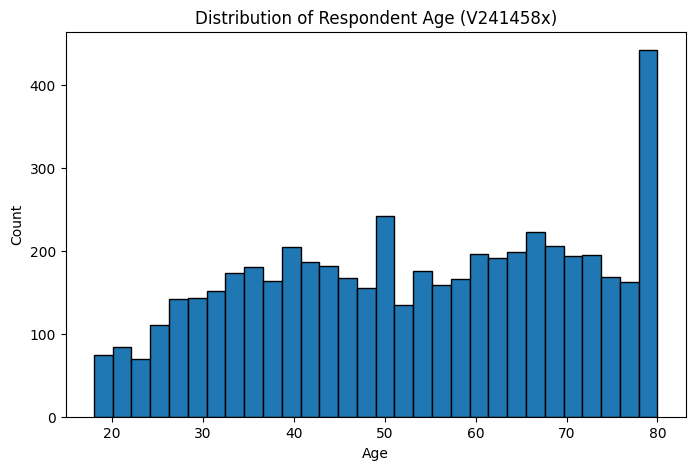

In [9]:
age = pd.to_numeric(anes2024["V241458x"])
age = age[(age >= 18) & (age <= 100)]

ax = age.plot(kind="hist", bins=30, edgecolor="black", figsize=(8, 5), title="Distribution of Respondent Age (V241458x)")
ax.set_xlabel("Age")
ax.set_ylabel("Count")

In [10]:
anes2024['V241458x'].value_counts()

V241458x
 80    333
-2     279
 66    118
 61    111
 40    108
      ... 
 24     38
 23     32
 18     28
 20     26
 19     21
Name: count, Length: 64, dtype: int64

In [11]:
anes2024['sex'] = anes2024['V241550'].map({1: 'Male', 2: 'Female'})
anes2024["sex"].value_counts()

sex
Female    2931
Male      2544
Name: count, dtype: int64

In [12]:
cces2024['gender4'].value_counts()

gender4
2    31992
1    27454
3      448
4      106
Name: count, dtype: int64

In [13]:
cces2024['sex'] = cces2024['gender4'].map({1: 'Male', 2: 'Female'})
cces2024["sex"].value_counts()

sex
Female    31992
Male      27454
Name: count, dtype: int64

In [14]:
gss['sex'] = gss['sex'].map({1: 'Male', 2: 'Female'})
gss["sex"].value_counts()

sex
Female    1823
Male      1467
Name: count, dtype: int64

In [15]:
cces2024['birthyr'].value_counts()

birthyr
1960    1618
1961    1589
1962    1556
1963    1485
1957    1429
        ... 
1929      12
1931      11
1932      11
1930       9
1928       3
Name: count, Length: 79, dtype: int64

In [16]:
cces2024['age_num'] = 2024 - cces2024['birthyr']
cces2024['age_num']

0        46
1        56
2        78
3        23
4        69
         ..
59995    74
59996    43
59997    69
59998    24
59999    73
Name: age_num, Length: 60000, dtype: int64

In [17]:
# Age group
cces2024['age'] = pd.cut(
    cces2024['age_num'],
    bins=[18, 35, 55, np.inf],
    labels=['18-34', '35-54', '55+']
)
cces2024['age'].value_counts()

age
55+      30013
35-54    17387
18-34    12132
Name: count, dtype: int64

In [18]:
# Age group: ANES V241458x is continuous age
anes2024['age'] = pd.cut(
    anes2024['V241458x'],
    bins=[18, 35, 55, np.inf],
    labels=['18-34', '35-54', '55+']
)

In [19]:
anes2024['age'].value_counts()

age
55+      2501
35-54    1699
18-34    1014
Name: count, dtype: int64

In [20]:
gss['age'].value_counts()


age
64.0    72
37.0    71
55.0    71
60.0    70
42.0    70
        ..
86.0    11
81.0    11
84.0    10
88.0     3
87.0     3
Name: count, Length: 72, dtype: int64

In [21]:
gss = gss[~gss["age"].astype(str).str.contains(r"No answer", na=False)].copy()
gss["age"] = gss["age"].replace("89 or older", 89)
gss["age_num"] = pd.to_numeric(gss["age"])
age_bins = [18, 35, 55, np.inf]
age_labels = ['18-34', '35-54', '55+']

# Create age group variable
gss["age"] = pd.cut(
    gss["age_num"],
    bins=age_bins,
    labels=age_labels
)
gss["age"].value_counts()

age
55+      1329
35-54    1084
18-34     765
Name: count, dtype: int64

In [22]:
# Income group: 1-14 -> <50k, 15-22 -> 50-100k, 23+ -> >100k
income_code = pd.to_numeric(anes2024['V241566x'])

anes2024['income'] = np.select(
    [
        income_code.between(1, 14),
        income_code.between(15, 22),
        income_code >= 23
    ],
    ['<50k', '50-100k', '100k+'],
    default=None
)
anes2024['income'].value_counts()

income
100k+      1954
<50k       1620
50-100k    1391
Name: count, dtype: int64

In [23]:
cces2024['faminc_new'].value_counts()

faminc_new
3.0     5849
4.0     5236
97.0    5119
9.0     4853
6.0     4817
5.0     4764
2.0     4373
11.0    4083
8.0     4058
10.0    3929
7.0     3679
1.0     3259
12.0    3037
13.0    1366
14.0     912
15.0     375
16.0     268
Name: count, dtype: int64

In [24]:
income_code = pd.to_numeric(cces2024['faminc_new'])

cces2024['income'] = np.select(
    [
        income_code.between(1, 5),
        income_code.between(6, 9),
        income_code.between(10, 16)
    ],
    ['<50k', '50-100k', '100k+'],
    default=None
)
cces2024['income'].value_counts()

income
<50k       23481
50-100k    17407
100k+      13970
Name: count, dtype: int64

In [25]:
gss['income16'].value_counts()

income16
26.0    355
20.0    268
22.0    245
19.0    236
21.0    235
18.0    185
23.0    165
24.0    130
17.0    126
16.0    123
25.0    107
9.0      97
15.0     91
10.0     78
13.0     77
1.0      67
14.0     62
12.0     52
11.0     51
2.0      48
8.0      34
3.0      26
5.0      25
4.0      18
7.0      16
6.0      14
Name: count, dtype: int64

In [26]:
income_code = pd.to_numeric(gss['income16'])

gss['income'] = np.select(
    [
        income_code.between(1, 18),
        income_code.between(19, 21),
        income_code.between(22, 26)
    ],
    ['<50k', '50-100k', '100k+'],
    default=None
)
gss['income'].value_counts()

income
<50k       1190
100k+      1002
50-100k     739
Name: count, dtype: int64

In [27]:
# Ethnicity: ANES V241501x → 1=White, Other = Non-White
anes2024['eth'] = anes2024['V241501x'].map({
    1: 'White', 2: 'Non-white', 3: 'Non-white', 4: 'Non-white', 5: 'Non-white', 6: 'Non-white'
})
anes2024['eth'].value_counts()

eth
White        3946
Non-white    1508
Name: count, dtype: int64

In [28]:
cces2024['race'].value_counts()

race
1    41443
2     7728
3     5150
4     1949
6     1947
7     1035
5      582
8      166
Name: count, dtype: int64

In [29]:
cces2024['eth'] = cces2024['race'].map({
    1: 'White', 2: 'Non-white', 3: 'Non-white', 4: 'Non-white', 5: 'Non-white', 6: 'Non-white',7: 'Non-white',8: 'Non-white'
})
cces2024['eth'].value_counts()

eth
White        41443
Non-white    18557
Name: count, dtype: int64

In [30]:
# gss ethnicity:
# Non-white if racecen1 is not White =OR racecen2 has a valid second-race entry
racecen1_num = pd.to_numeric(gss["racecen1"])
racecen1_is_white = racecen1_num.eq(1) 

racecen2_num = pd.to_numeric(gss["racecen2"])

# valid second race = not missing and not one of missing labels, and not negative numeric code
valid_second_race = (
    gss["racecen2"].notna()
    & ~(racecen2_num < 0).fillna(False)
)

gss["eth"] = np.where((~racecen1_is_white) | valid_second_race, "Non-white", "White")
gss["eth"].value_counts(dropna=False)

eth
White        2218
Non-white    1091
Name: count, dtype: int64

In [31]:
# Education: ANES V241465x → Non-Colledge,Colledge
anes2024['education'] = anes2024['V241465x'].map({
    1: 'Non-college', 2: 'Non-college', 3: 'Non-college', 4: 'College', 5: 'College'
})
anes2024['education'].value_counts()

education
Non-college    2994
College        2471
Name: count, dtype: int64

In [32]:
cces2024['educ'].value_counts()

educ
2    15983
3    13961
5    13297
6     7960
4     6666
1     2133
Name: count, dtype: int64

In [33]:
cces2024['education'] = cces2024['educ'].map({
    1: 'Non-college', 2: 'Non-college', 3: 'Non-college', 4: 'College', 5: 'College', 6: 'College'
})
cces2024['education'].value_counts()

education
Non-college    32077
College        27923
Name: count, dtype: int64

In [34]:
gss['degree'].value_counts()

degree
1.0    1506
3.0     721
4.0     474
0.0     306
2.0     299
Name: count, dtype: int64

In [35]:
gss['education'] = gss['degree'].map({
    0: 'Non-college', 1: 'Non-college', 2: 'College', 3: 'College', 4: 'College'
})
gss['education'].value_counts()

education
Non-college    1812
College        1494
Name: count, dtype: int64

In [36]:
# Vote: ANES V241106x
anes2024['vote'] = anes2024['V241106x'].map({
    1: 'StayHome', 2: 'Democratic', 3: 'Republican', 4: 'Other'
})
anes2024['vote'].value_counts()

vote
Democratic    2433
Republican    1821
StayHome      1155
Other           65
Name: count, dtype: int64

In [37]:
cces2024['vote'] = cces2024['presvote20post'].map({
    1: 'Democratic', 2: 'Republican', 3: 'Other', 4: 'Other', 5: 'Other', 6: 'StayHome'
})
cces2024['vote'].value_counts()

vote
Democratic    26942
Republican    19433
StayHome      11921
Other          1660
Name: count, dtype: int64

In [38]:
cces2024['presvote20post'].value_counts()

presvote20post
1.0    26942
2.0    19433
6.0    11921
3.0      784
5.0      610
4.0      266
Name: count, dtype: int64

In [39]:
gss["pres20"].value_counts()

pres20
1.0    1188
2.0     874
3.0      53
4.0      13
Name: count, dtype: int64

In [40]:
gss['vote'] = gss['pres20'].map({
    1: 'Democratic', 2: 'Republican', 3: 'Other', 4: 'StayHome'
})
gss['vote'].value_counts()

vote
Democratic    1188
Republican     874
Other           53
StayHome        13
Name: count, dtype: int64

In [41]:
# State: ANES V242058x
# state mapping data for anes
codes = [-1] + list(range(1, 3)) + list(range(4, 7)) + list(range(8, 14)) + \
        list(range(15, 43)) + list(range(44, 52)) + list(range(53, 57))

levels = [
    np.nan, 'Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California', 'Colorado', 
    'Connecticut', 'Delaware', 'District of Columbia', 'Florida', 'Georgia', 
    'Hawaii', 'Idaho', 'Illinois', 'Indiana', 'Iowa', 'Kansas', 'Kentucky', 
    'Louisiana', 'Maine', 'Maryland', 'Massachusetts', 'Michigan', 'Minnesota', 
    'Mississippi', 'Missouri', 'Montana', 'Nebraska', 'Nevada', 'New Hampshire', 
    'New Jersey', 'New Mexico', 'New York', 'North Carolina', 'North Dakota', 
    'Ohio', 'Oklahoma', 'Oregon', 'Pennsylvania', 'Rhode Island', 'South Carolina', 
    'South Dakota', 'Tennessee', 'Texas', 'Utah', 'Vermont', 'Virginia', 
    'Washington', 'West Virginia', 'Wisconsin', 'Wyoming'
]

# Create a dictionary for the mapping
state_map = dict(zip(codes, levels))

# Apply the mapping to anes
anes2024['state'] = anes2024['V242058x'].map(state_map).astype('category')

In [42]:
anes2024['V240108b'].value_counts()

V240108b
                     757
5.00000000498223     105
.238504135225957       2
.683671970390806       2
.859994166460876       2
                    ... 
.596674076518462       1
.0948685952731166      1
1.90730910362323       1
2.56436072555069       1
1.34915930327876       1
Name: count, Length: 4658, dtype: int64

In [43]:
codes = [-1] + list(range(1, 3)) + list(range(4, 7)) + list(range(8, 14)) + \
        list(range(15, 43)) + list(range(44, 52)) + list(range(53, 57))

levels = [
    np.nan, 'Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California', 'Colorado', 
    'Connecticut', 'Delaware', 'District of Columbia', 'Florida', 'Georgia', 
    'Hawaii', 'Idaho', 'Illinois', 'Indiana', 'Iowa', 'Kansas', 'Kentucky', 
    'Louisiana', 'Maine', 'Maryland', 'Massachusetts', 'Michigan', 'Minnesota', 
    'Mississippi', 'Missouri', 'Montana', 'Nebraska', 'Nevada', 'New Hampshire', 
    'New Jersey', 'New Mexico', 'New York', 'North Carolina', 'North Dakota', 
    'Ohio', 'Oklahoma', 'Oregon', 'Pennsylvania', 'Rhode Island', 'South Carolina', 
    'South Dakota', 'Tennessee', 'Texas', 'Utah', 'Vermont', 'Virginia', 
    'Washington', 'West Virginia', 'Wisconsin', 'Wyoming'
]

# Create a dictionary for the mapping
state_map = dict(zip(codes, levels))

# Apply the mapping to cces2024
cces2024['state'] = cces2024['inputstate'].map(state_map).astype('category')

In [44]:
states = cces2024['inputstate'].dropna().sort_values().unique()
print(states)

[ 1  2  4  5  6  8  9 10 11 12 13 15 16 17 18 19 20 21 22 23 24 25 26 27
 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 44 45 46 47 48 49 50 51 53
 54 55 56]


In [45]:
cces2024['state'].value_counts() 

state
California              4900
Texas                   4816
Florida                 4402
New York                3453
Pennsylvania            3040
Ohio                    2564
Illinois                2320
Georgia                 2055
Michigan                1951
North Carolina          1913
Virginia                1611
New Jersey              1604
Arizona                 1495
Washington              1382
Tennessee               1371
Wisconsin               1334
Missouri                1323
Indiana                 1267
Massachusetts           1119
Maryland                1068
Colorado                1055
Minnesota               1016
Oregon                  1009
South Carolina           992
Alabama                  901
Kentucky                 887
Nevada                   739
Louisiana                709
Oklahoma                 701
Iowa                     615
Connecticut              594
Arkansas                 532
Utah                     507
Mississippi              503
Kansas  

# find the time window where most observation are collected

In [46]:
df = pd.read_pickle('../../generated_data/feature_extraction/preprocessed_cleaned_all_result.pkl')

In [47]:
df['time_window_start'] = pd.to_datetime(df['time_window_start']).dt.tz_localize(None)
time_window = df['time_window_start'].unique()
time_window

<DatetimeArray>
['2023-11-05 00:00:00', '2023-11-19 00:00:00', '2023-12-03 00:00:00',
 '2023-12-17 00:00:00', '2023-12-31 00:00:00', '2024-01-14 00:00:00',
 '2024-01-28 00:00:00', '2024-02-11 00:00:00', '2024-02-25 00:00:00',
 '2024-03-10 00:00:00', '2024-04-07 00:00:00', '2024-10-06 00:00:00',
 '2024-10-20 00:00:00', '2024-03-24 00:00:00', '2024-04-21 00:00:00',
 '2024-05-05 00:00:00', '2024-05-19 00:00:00', '2024-06-16 00:00:00',
 '2024-06-30 00:00:00', '2024-07-14 00:00:00', '2024-07-28 00:00:00',
 '2024-08-11 00:00:00', '2024-08-25 00:00:00', '2024-09-08 00:00:00',
 '2024-09-22 00:00:00', '2024-06-02 00:00:00']
Length: 26, dtype: datetime64[ns]

for time stamps in the list time_window, use them as cut points and form bins of time windows, then check the time stamp in anes2024['V243050'], which bin of time window it falls into, in the end print a table that counts the number of rows where anes2024['V243050'] fall into the bin in each bin in time_window

In [48]:
cut_points = pd.DatetimeIndex(time_window).sort_values().unique()

obs_time = pd.to_datetime(anes2024["V243050"].astype(str), format="%Y%m%d", errors="coerce")
last_cut = cut_points.max()
upper_bound = last_cut + pd.Timedelta(days=14)

bins = cut_points.append(pd.DatetimeIndex([upper_bound]))

bin_labels = [
    f"[{bins[i].date()} , {bins[i+1].date()})"
    for i in range(len(bins) - 1)
]

bin_assignments = pd.cut(
    obs_time,
    bins=bins,
    labels=bin_labels,
    right=False,
    include_lowest=True
)

anes2024["time_window_bin"] = bin_assignments

bin_counts = (
    bin_assignments.value_counts(dropna=False)
    .reindex(bin_labels, fill_value=0)
    .reset_index()
)
bin_counts.columns = ["time_window_bin", "row_count"]

bin_counts

,time_window_bin,row_count
0,"[2023-11-05 , 2023-11-19)",0
1,"[2023-11-19 , 2023-12-03)",0
2,"[2023-12-03 , 2023-12-17)",0
3,"[2023-12-17 , 2023-12-31)",0
4,"[2023-12-31 , 2024-01-14)",0
5,"[2024-01-14 , 2024-01-28)",0
6,"[2024-01-28 , 2024-02-11)",0
7,"[2024-02-11 , 2024-02-25)",0
8,"[2024-02-25 , 2024-03-10)",0
9,"[2024-03-10 , 2024-03-24)",0


In [49]:
type(cces2024['starttime'][1])

str

In [50]:
cces2024['starttime'].value_counts()

starttime
2024-10-12 15:19:00    4
2024-10-15 19:29:52    4
2024-10-16 02:59:55    3
2024-10-15 23:21:35    3
2024-10-15 22:00:10    3
                      ..
2024-11-03 19:13:54    1
2024-11-04 00:29:16    1
2024-11-04 00:40:30    1
2024-11-04 03:08:54    1
2024-11-02 01:56:23    1
Name: count, Length: 58417, dtype: int64

In [51]:
obs_time

0      2024-08-12
1      2024-08-18
2      2024-08-09
3      2024-08-15
4      2024-08-14
          ...    
5516   2024-10-24
5517   2024-09-27
5518   2024-10-06
5519   2024-11-01
5520   2024-09-17
Name: V243050, Length: 5521, dtype: datetime64[ns]

In [52]:
cut_points = pd.DatetimeIndex(time_window).sort_values().unique()

obs_time = pd.to_datetime(cces2024["starttime"]).dt.normalize()
last_cut = cut_points.max()
upper_bound = last_cut + pd.Timedelta(days=14)

bins = cut_points.append(pd.DatetimeIndex([upper_bound]))

bin_labels = [
    f"[{bins[i].date()} , {bins[i+1].date()})"
    for i in range(len(bins) - 1)
]

bin_assignments = pd.cut(
    obs_time,
    bins=bins,
    labels=bin_labels,
    right=False,
    include_lowest=True
)

cces2024["time_window_bin"] = bin_assignments

bin_counts = (
    bin_assignments.value_counts(dropna=False)
    .reindex(bin_labels, fill_value=0)
    .reset_index()
)
bin_counts.columns = ["time_window_bin", "row_count"]

bin_counts

,time_window_bin,row_count
0,"[2023-11-05 , 2023-11-19)",0
1,"[2023-11-19 , 2023-12-03)",0
2,"[2023-12-03 , 2023-12-17)",0
3,"[2023-12-17 , 2023-12-31)",0
4,"[2023-12-31 , 2024-01-14)",0
5,"[2024-01-14 , 2024-01-28)",0
6,"[2024-01-28 , 2024-02-11)",0
7,"[2024-02-11 , 2024-02-25)",0
8,"[2024-02-25 , 2024-03-10)",0
9,"[2024-03-10 , 2024-03-24)",0


In [53]:
gss['dateintv'].value_counts()

dateintv
523     88
1017    64
522     62
1018    48
729     47
        ..
818      3
1001     3
1005     2
1003     1
405      1
Name: count, Length: 242, dtype: int64

In [54]:
def convert_dateintv_to_datetime(dateintv):
    """
    Convert GSS dateintv format (MMDD) to datetime.
    """
    
    # label non-numeric entries (e.g., ".n:  No answer") to NaT
    if isinstance(dateintv, str):
        digits = re.sub(r"\D", "", dateintv)
        if digits == "":
            return pd.NaT
        dateintv = digits
    
    dateintv_num = pd.to_numeric(dateintv)
    
    dateintv_str = str(int(dateintv_num)).zfill(4)  
    month = int(dateintv_str[:2])
    day = int(dateintv_str[2:])
    
    # Determine year based on context 
    year = 2024
    
    return pd.to_datetime(f"{year}-{month:02d}-{day:02d}")

In [55]:
def convert_dateintv_to_datetime(dateintv):
    """
    Convert GSS dateintv format (MMDD) to datetime.
    """
    if pd.isna(dateintv):
        return pd.NaT
    
    # Coerce non-numeric entries (e.g., ".n:  No answer") to NaT
    if isinstance(dateintv, str):
        digits = re.sub(r"\D", "", dateintv)
        if digits == "":
            return pd.NaT
        dateintv = digits
    
    dateintv_num = pd.to_numeric(dateintv, errors="coerce")
    if pd.isna(dateintv_num):
        return pd.NaT
    
    dateintv_str = str(int(dateintv_num)).zfill(4)  # Ensure 4 digits (e.g., '0427' for April 27)
    month = int(dateintv_str[:2])
    day = int(dateintv_str[2:])
    
    # Determine year based on context 
    year = 2024
    
    try:
        return pd.to_datetime(f"{year}-{month:02d}-{day:02d}")
    except:
        return pd.NaT

In [56]:
gss['interview_date'] = gss['dateintv'].apply(convert_dateintv_to_datetime)
gss['interview_date'].value_counts()

interview_date
2024-05-23    88
2024-10-17    64
2024-05-22    62
2024-10-18    48
2024-07-29    47
              ..
2024-08-18     3
2024-10-01     3
2024-10-05     2
2024-10-03     1
2024-04-05     1
Name: count, Length: 242, dtype: int64

In [57]:
cut_points

DatetimeIndex(['2023-11-05', '2023-11-19', '2023-12-03', '2023-12-17',
               '2023-12-31', '2024-01-14', '2024-01-28', '2024-02-11',
               '2024-02-25', '2024-03-10', '2024-03-24', '2024-04-07',
               '2024-04-21', '2024-05-05', '2024-05-19', '2024-06-02',
               '2024-06-16', '2024-06-30', '2024-07-14', '2024-07-28',
               '2024-08-11', '2024-08-25', '2024-09-08', '2024-09-22',
               '2024-10-06', '2024-10-20'],
              dtype='datetime64[ns]', freq=None)

In [58]:
# gss time window
cut_points = pd.DatetimeIndex(time_window).sort_values().unique()
obs_time = gss["interview_date"]

last_cut = cut_points.max()
upper_bound = last_cut + pd.Timedelta(days=14)

# Safety: ensure upper bound is strictly greater than the last cut point
if upper_bound <= last_cut:
    upper_bound = last_cut + pd.Timedelta(days=1)

bins = cut_points.append(pd.DatetimeIndex([upper_bound]))

bin_labels = [
    f"[{bins[i].date()} , {bins[i+1].date()})"
    for i in range(len(bins) - 1)
]

bin_assignments = pd.cut(
    obs_time,
    bins=bins,
    labels=bin_labels,
    right=False,
    include_lowest=True
)

gss["time_window_bin"] = bin_assignments

bin_counts = (
    bin_assignments.value_counts(dropna=False)
    .reindex(bin_labels, fill_value=0)
    .reset_index()
)
bin_counts.columns = ["time_window_bin", "row_count"]

bin_counts

,time_window_bin,row_count
0,"[2023-11-05 , 2023-11-19)",0
1,"[2023-11-19 , 2023-12-03)",0
2,"[2023-12-03 , 2023-12-17)",0
3,"[2023-12-17 , 2023-12-31)",0
4,"[2023-12-31 , 2024-01-14)",0
5,"[2024-01-14 , 2024-01-28)",0
6,"[2024-01-28 , 2024-02-11)",0
7,"[2024-02-11 , 2024-02-25)",0
8,"[2024-02-25 , 2024-03-10)",0
9,"[2024-03-10 , 2024-03-24)",0


In [59]:
anes2024['V243050'].notna().sum()


np.int64(5521)

In [60]:
anes2024['V243052'].notna().sum()


np.int64(5521)

count how many rows has value in 'V243050' different from value in 'V243052'

In [61]:
mask = anes2024['V243050'].notna() & anes2024['V243052'].notna()
diff_rows = anes2024.loc[
    mask & (anes2024['V243050'] != anes2024['V243052']),
    ['V243050', 'V243052']
]

diff_rows

,V243050,V243052
0,20240812,20240812
1,20240818,20240818
2,20240809,20240809
3,20240815,20240815
4,20240814,20240814
...,...,...
5445,20240810,20240829
5452,20240829,20240901
5457,20240916,20241004
5482,20240808,20240903


In [62]:
anes2024['V243054'].notna().sum()

np.int64(5521)

count values that are not in a day format (yyyymmdd) in anes2024['V243052']

In [63]:
v243052_str = pd.to_numeric(anes2024['V243052'], errors='coerce').astype('Int64').astype('string')

is_yyyymmdd = v243052_str.str.fullmatch(r'\d{8}')
is_real_date = pd.to_datetime(v243052_str, format='%Y%m%d', errors='coerce').notna()

invalid_count = (anes2024['V243052'].notna() & ~(is_yyyymmdd & is_real_date)).sum()
invalid_count

np.int64(298)

In [64]:
v243052_str = pd.to_numeric(anes2024['V243052'], errors='coerce').astype('Int64').astype('string')

is_yyyymmdd = v243052_str.str.fullmatch(r'\d{8}')
is_real_date = pd.to_datetime(v243052_str, format='%Y%m%d', errors='coerce').notna()

invalid_count = (anes2024['V243052'].notna() & ~(is_yyyymmdd & is_real_date)).sum()
invalid_count

np.int64(298)

In [65]:
anes2024['V243052']

0       20240812
1       20240818
2       20240809
3       20240815
4       20240814
          ...   
5516    20241024
5517    20240927
5518    20241006
5519    20241101
5520    20240917
Name: V243052, Length: 5521, dtype: object

In [66]:
anes2024['V243054'].value_counts()

V243054
         .    5283
20241028        49
20241029        41
20241026        35
20241030        25
20241027        23
20241025        18
20241101         7
20241024         7
20241103         6
20241023         6
20241031         6
20241104         4
20241102         3
20241124         1
20240403         1
                 1
20241105         1
20241022         1
20240929         1
20241130         1
20240828         1
Name: count, dtype: int64

# clean up belief columns

In [67]:
mapper = pd.read_excel("../../generated_data/new_cleaned_feature_match_updated_state_level.xlsx")

build a reverse function that given a column name, take all the positive value and reverse(if there are 5 scales, then the updated version has 1 become 5, 2 become 4 etc), make it adaptive with different scales_

In [68]:
def reverse_scale(df, column_name):
    """
    Reverse a Likert-style scale in df[column_name] adaptively.
    Positive values are reversed (1->max, 2->max-1, ...).
    NaN, zero, and negative values are preserved.
    """
    col = df[column_name]
    positive_vals = col[col > 0]

    max_val = positive_vals.max()
    mask = col > 0
    df.loc[mask, column_name] = max_val + 1 - col[mask]

    return df


# OPINION ON THE EXTENT TO WHICH THIS INDIVIDUAL FEELS IT IS JUSTIFIED FOR PEOPLE TO USE VIOLENCE TO PURSUE THEIR POLITICAL GOALS IN THIS COUNTRY

In [69]:
anes2024['V241579'].value_counts()

V241579
 1    4427
 2     281
 3     270
-1     245
 5     119
 4      95
-9      59
-5      25
Name: count, dtype: int64

In [70]:
anes2024=reverse_scale(anes2024, 'V241579')
anes2024

,version,V240001,V200001,V160001_orig,V240002a,V240002b,V240002c,V240003,V240101a,V240101b,...,V245017,V245018,sex,age,income,eth,education,vote,state,time_window_bin
0,ANES2024TimeSeries_20250808,140001,200015,401318,2,2,2,1,,,...,-1,-1,Male,35-54,100k+,Non-white,College,Republican,Oklahoma,"[2024-08-11 , 2024-08-25)"
1,ANES2024TimeSeries_20250808,140002,200022,300261,2,2,2,1,,,...,-1,-1,Female,35-54,100k+,Non-white,Non-college,StayHome,Idaho,"[2024-08-11 , 2024-08-25)"
2,ANES2024TimeSeries_20250808,140003,200039,400181,2,2,2,1,,,...,-1,-1,Female,35-54,100k+,White,Non-college,Democratic,Virginia,"[2024-07-28 , 2024-08-11)"
3,ANES2024TimeSeries_20250808,140004,200046,300171,2,2,2,1,,,...,-1,-1,Male,35-54,<50k,Non-white,Non-college,StayHome,California,"[2024-08-11 , 2024-08-25)"
4,ANES2024TimeSeries_20250808,140005,200053,405145,2,2,2,1,,,...,-1,-1,Male,55+,50-100k,White,College,StayHome,Colorado,"[2024-08-11 , 2024-08-25)"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5516,ANES2024TimeSeries_20250808,399764,-1,-1,1,-6,1,3,0.117236,,...,-1,-1,Female,NaN,<50k,NaN,College,NaN,California,"[2024-10-20 , 2024-11-03)"
5517,ANES2024TimeSeries_20250808,399815,-1,-1,1,5,2,3,1.501748,1.15260127111406,...,1,0,Female,55+,50-100k,White,Non-college,Democratic,Minnesota,"[2024-09-22 , 2024-10-06)"
5518,ANES2024TimeSeries_20250808,399830,-1,-1,1,-6,1,3,1.114477,,...,-1,-1,Female,NaN,<50k,Non-white,Non-college,NaN,Virginia,"[2024-10-06 , 2024-10-20)"
5519,ANES2024TimeSeries_20250808,399841,-1,-1,4,4,2,3,1.179447,1.1924221171493,...,1,2,Male,18-34,50-100k,Non-white,College,Democratic,New Jersey,"[2024-10-20 , 2024-11-03)"


# OPINION ON THE NUMBER OF IMMIGRANTS IN AMERICA

In [71]:
gss['letin1a'].value_counts()

letin1a
3.0    1035
5.0     959
4.0     618
2.0     354
1.0     221
Name: count, dtype: int64

In [72]:
gss["LETIN1A"] = gss["letin1a"]

In [73]:
gss['LETIN1A'].value_counts(dropna=False)

LETIN1A
3.0    1035
5.0     959
4.0     618
2.0     354
1.0     221
NaN     122
Name: count, dtype: int64

# belief OPINION ON THE STATEMENT << IMMIGRANTS INCREASE CRIME RATES >>

In [74]:
anes2024['V242453'].value_counts()

V242453
 2    1223
 3     954
 5     950
 1     812
 4     748
-6     472
-1     245
-5      52
-7      40
-9      21
-8       4
Name: count, dtype: int64

In [75]:
# Recode V242453:
# original 3 -> -1, original 4 -> 3, original 5 -> 4
anes2024["V242453"] = anes2024["V242453"].replace({
    3: -1,
    4: 3,
    5: 4
})

anes2024["V242453"].value_counts(dropna=False)

V242453
 2    1223
-1    1199
 4     950
 1     812
 3     748
-6     472
-5      52
-7      40
-9      21
-8       4
Name: count, dtype: int64

In [76]:
gss['immcrime1'].value_counts()

immcrime1
4.0    496
3.0    401
2.0    296
5.0    225
1.0    127
Name: count, dtype: int64

In [77]:
gss["IMMCRIME1"] = gss['immcrime1'].replace({
    3: -1,
    4: 3,
    5: 4
})

gss["IMMCRIME1"].value_counts(dropna=False)

IMMCRIME1
 NaN    1764
 3.0     496
-1.0     401
 2.0     296
 4.0     225
 1.0     127
Name: count, dtype: int64

# OPINION ON THE STATEMENT << IMMIGRANTS TAKE JOBS AWAY FROM PEOPLE WHO WERE BORN IN THE USA >>

In [78]:
gss['immjobs1'].value_counts()

immjobs1
4.0    562
3.0    343
2.0    308
5.0    241
1.0    109
Name: count, dtype: int64

In [79]:
gss["IMMJOBS1"] = gss['immjobs1'].replace({
    3: -1,
    4: 3,
    5: 4
})

gss["IMMJOBS1"].value_counts(dropna=False)

IMMJOBS1
 NaN    1746
 3.0     562
-1.0     343
 2.0     308
 4.0     241
 1.0     109
Name: count, dtype: int64

# OPINION ON WHAT SHOULD BE DONE WITH ILLEGAL IMMIGRANTS

In [80]:
gss['immfate'].value_counts()

immfate
1.0    1303
3.0     547
2.0     320
Name: count, dtype: int64

In [81]:
gss["IMMFATE"] = gss["immfate"]

In [82]:
anes2024['V241386'].value_counts()

V241386
 3    2475
 1    1259
 2     826
 4     668
-1     245
-9      42
-8       6
Name: count, dtype: int64

In [83]:
anes2024["V241386"] = anes2024["V241386"].replace({
    1: 3,
    3: 1,
    4: 1
})

anes2024["V241386"].value_counts(dropna=False)

V241386
 1    3143
 3    1259
 2     826
-1     245
-9      42
-8       6
Name: count, dtype: int64

# OPINION ON WHETHER DIVORCE IN THE USA SHOULD BE EASIER OR MORE DIFFICULT TO OBTAIN THAN IT IS

In [84]:
gss['divlaw'].value_counts()

divlaw
1.0    455
2.0    243
3.0    205
Name: count, dtype: int64

In [85]:
gss["DIVLAW"] = gss["divlaw"].replace({
    2: 3,
    3: 2
})

gss["DIVLAW"].value_counts(dropna=False)

DIVLAW
NaN    2406
1.0     455
3.0     243
2.0     205
Name: count, dtype: int64

# OPINION ON THE FOLLOWING STATEMENT << IT SHOULD BE ACCEPTABLE FOR A PREGNANT WOMAN TO OBTAIN A LEGAL ABORTION IF A WOMAN WANTS IT, FOR ANY REASON>>

In [86]:
cces2024['CC24_324a'].value_counts()

CC24_324a
1.0    39048
2.0    20923
Name: count, dtype: int64

In [87]:
gss['ABANY'] = gss['abany']
gss['ABANY'].value_counts()

ABANY
1.0    1281
2.0     859
Name: count, dtype: int64

# OPINION ON THE FOLLOWING STATEMENT << HOMOSEXUAL COUPLES SHOULD HAVE THE RIGHT TO MARRY ONE ANOTHER >>

In [88]:
gss['marsame'].value_counts()

marsame
1.0    460
2.0    262
3.0    175
5.0    147
4.0     83
Name: count, dtype: int64

In [89]:
gss["MARSAME"] = gss['marsame'].replace({
    3: -1,
    4: 3,
    5: 4
})

gss["MARSAME"].value_counts(dropna=False)

MARSAME
 NaN    2182
 1.0     460
 2.0     262
-1.0     175
 4.0     147
 3.0      83
Name: count, dtype: int64

In [90]:
anes2024['V241385x'].value_counts()

V241385x
-1    2888
 1    1200
 4     526
 2     344
 7     322
 6     104
 3      79
 5      39
-2      19
Name: count, dtype: int64

In [91]:
anes2024['V241385x'] = anes2024['V241385x'].replace({
    3: 2,
    4: -1,
    5: 3,
    6: 3,
    7: 4
})

anes2024['V241385x'].value_counts(dropna=False)

V241385x
-1    3414
 1    1200
 2     423
 4     322
 3     143
-2      19
Name: count, dtype: int64

# OPINION ON THE STATEMENT << IT IS MUCH BETTER FOR EVERYONE INVOLVED IF THE MAN IS THE ACHIEVER OUTSIDE THE HOME AND THE WOMAN TAKES CARE OF THE HOME AND FAMILY >>

In [92]:
anes2024['V242279x'].value_counts()

V242279x
 4    3184
 1     630
-6     472
 2     464
-1     245
 6     168
 3     114
 7      86
 5      52
-7      40
-2      37
-5      29
Name: count, dtype: int64

In [93]:
anes2024['V242279x'] = anes2024['V242279x'].replace({
    3: 2,
    4: -1,
    5: 3,
    6: 3,
    7: 4
}
)
anes2024['V242279x'].value_counts(dropna=False)

V242279x
-1    3429
 1     630
 2     578
-6     472
 3     220
 4      86
-7      40
-2      37
-5      29
Name: count, dtype: int64

In [94]:
gss['FEFAM'] = gss['fefam']
gss['FEFAM'].value_counts()

FEFAM
3.0    899
4.0    604
2.0    492
1.0    167
Name: count, dtype: int64

# WILLINGNESS TO PAY HIGHER TAXES TO IMPROVE THE LEVEL OF HEALTH CARE FOR ALL PEOPLE IN THE UNITED STATES

In [95]:
anes2024['V242353x'].value_counts()

V242353x
 4    1383
 2    1223
 1    1117
-6     472
 6     325
 3     296
-1     245
 7     241
 5     107
-7      40
-2      39
-5      33
Name: count, dtype: int64

In [96]:
anes2024['V242353x'] = anes2024['V242353x'].replace({
    3: 2,
    4: -1,
    5: 3,
    6: 3,
    7: 4
}
)
anes2024['V242353x'].value_counts(dropna=False)

V242353x
-1    1628
 2    1519
 1    1117
-6     472
 3     432
 4     241
-7      40
-2      39
-5      33
Name: count, dtype: int64

# OPINION ON THE FOLLOWING STATEMENT << OVERALL, VACCINATIONS DO MORE HARM THAN GOOD >>

In [97]:
anes2024['V242357x'].value_counts()

V242357x
 1    2111
 4     875
 2     836
-6     517
 6     326
 3     326
 7     275
 5     139
-2      42
-7      40
-5      34
Name: count, dtype: int64

In [98]:
# first collaspe to 5 point scale
anes2024['V242357x'] = anes2024['V242357x'].replace({
    3: 2,
    4: -1,
    5: 3,
    6: 3,
    7: 4
}
)
anes2024['V242357x'].value_counts(dropna=False)

V242357x
 1    2111
 2    1162
-1     875
-6     517
 3     465
 4     275
-2      42
-7      40
-5      34
Name: count, dtype: int64

In [99]:
# then reverse
anes2024=reverse_scale(anes2024, 'V242357x')
anes2024['V242357x'].value_counts(dropna=False)

V242357x
 4    2111
 3    1162
-1     875
-6     517
 2     465
 1     275
-2      42
-7      40
-5      34
Name: count, dtype: int64

# OPINION ON WHETHER COURTS IN THE USERS'S AREA DEAL TOO HARSHLY OR NOT HARSHLY ENOUGH WITH CRIMINALS

In [100]:
gss['courts'].value_counts()

courts
2.0    473
3.0    211
1.0    128
Name: count, dtype: int64

In [101]:
gss["COURTS"] = gss["courts"].replace({
    2: 3,
    3: 2
})

gss["COURTS"].value_counts(dropna=False)

COURTS
NaN    2497
3.0     473
2.0     211
1.0     128
Name: count, dtype: int64

# OPINION ON MARIJUANA LEGALISATION

In [102]:
gss['GRASS'] = gss['grass']
gss['GRASS'].value_counts()

GRASS
1.0    591
2.0    271
Name: count, dtype: int64

# OPINION ON THE STATEMENT << MEN ARE BETTER SUITED EMOTIONALLY FOR POLITICS THAN ARE MOST WOMEN >>

In [103]:
gss['FEPOLV'] = gss['fepolv']
gss['FEPOLV'].value_counts()

FEPOLV
2.0    419
1.0     81
Name: count, dtype: int64

# OPINION ON THE STATEMENT << A PERSON SHOULD REQUIRE A POLICE PERMIT BEFORE HE OR SHE COULD BUY A GUN >>

In [104]:
gss['GUNLAW'] = gss['gunlaw']
gss['GUNLAW'].value_counts()

GUNLAW
1.0    1523
2.0     668
Name: count, dtype: int64

# OPINION ON WHETHER WHITE PEOPLE BENEFIT FROM SOCIETAL ADVANTAGES NOT AVAILABLE TO BLACK PEOPLE

In [105]:
cces2024['CC24_440a'].value_counts()

CC24_440a
1.0    14690
2.0    11638
5.0     9037
3.0     8675
4.0     5230
Name: count, dtype: int64

In [106]:
cces2024['CC24_440a'] = cces2024['CC24_440a'].replace({
    3: -1,
    4: 3,
    5: 4
})

cces2024['CC24_440a'].value_counts(dropna=False)

CC24_440a
 1.0    14690
 2.0    11638
 NaN    10730
 4.0     9037
-1.0     8675
 3.0     5230
Name: count, dtype: int64

# OPINION ON THE STATEMENT << BECAUSE OF PAST DISCRIMINATION, BLACK PEOPLE SHOULD BE GIVEN PREFERENCE IN HIRING AND PROMOTION >>

In [107]:
gss['AFFRMACT'] = gss['affrmact']
gss['AFFRMACT'].value_counts()

AFFRMACT
4.0    884
3.0    573
1.0    333
2.0    220
Name: count, dtype: int64

# SATISFACTION WITH THE WAY DEMOCRACY IS WORKING IN THE US

In [108]:
anes2024['V242439'].value_counts()

V242439
 2    2668
 4    1272
-6     472
 1     449
 5     287
-1     245
-5      48
-7      40
-9      30
-8      10
Name: count, dtype: int64

In [109]:
anes2024['V242439'] = anes2024['V242439'].replace({
    3: -1,
    4: 3,
    5: 4
})

anes2024['V242439'].value_counts(dropna=False)

V242439
 2    2668
 3    1272
-6     472
 1     449
 4     287
-1     245
-5      48
-7      40
-9      30
-8      10
Name: count, dtype: int64

In [110]:
gss['SATDEMOC'] = gss['satdemoc']
gss['SATDEMOC'].value_counts()

SATDEMOC
3.0    1235
2.0    1156
4.0     576
1.0     196
Name: count, dtype: int64

# TRUST IN THE INFORMATION THAT COMES FROM ESTABLISHED NEWS ORGANIZATIONS

In [111]:
gss['biasnews'].value_counts()

biasnews
2.0    610
1.0    584
3.0    243
4.0     62
5.0     13
Name: count, dtype: int64

In [112]:
gss=reverse_scale(gss, 'biasnews')
gss['biasnews'].value_counts()

biasnews
4.0    610
5.0    584
3.0    243
2.0     62
1.0     13
Name: count, dtype: int64

In [113]:
# norm gss['biasnews'] from 1-5 to 1-4 with the normalization formula
gss['BIASNEWS'] = (gss['biasnews'] - 1) / (5 - 1) * (4 - 1) + 1
gss['BIASNEWS'].value_counts()

BIASNEWS
3.25    610
4.00    584
2.50    243
1.75     62
1.00     13
Name: count, dtype: int64

In [114]:
anes2024['V241335'].value_counts()

V241335
 3    1732
 2    1523
 1    1204
 4     561
-1     245
 5     233
-9      20
-8       3
Name: count, dtype: int64

In [115]:
anes2024['V241335'] = anes2024['V241335'].replace({
    5: 4
})

anes2024['V241335'].value_counts(dropna=False)

V241335
 3    1732
 2    1523
 1    1204
 4     794
-1     245
-9      20
-8       3
Name: count, dtype: int64

In [116]:
anes2024=reverse_scale(anes2024, 'V241335')
anes2024['V241335'].value_counts()

V241335
 2    1732
 3    1523
 4    1204
 1     794
-1     245
-9      20
-8       3
Name: count, dtype: int64

# TRUST IN THE INFORMATION THAT COMES FROM INDEPENDENT MEDIA SOURCES, INCLUDING PODCASTS, BLOGS, SOCIAL-MEDIA, etc.

In [117]:
gss['smnews'].value_counts()

smnews
3.0    491
2.0    486
1.0    404
4.0     55
Name: count, dtype: int64

In [118]:
gss=reverse_scale(gss, 'smnews')
gss['SMNEWS'] = gss['smnews']
gss['SMNEWS'].value_counts()

SMNEWS
2.0    491
3.0    486
4.0    404
1.0     55
Name: count, dtype: int64

# OPINION ON THE STATEMENT << CLIMATE CHANGE IS A MAJOR THREAT TO THE UNITED STATES >>

In [119]:
anes2024['V242174'].value_counts()

V242174
 1    1669
 2    1163
 3     953
 4     631
 5     519
-6     517
-7      40
-5      16
-9      10
-8       3
Name: count, dtype: int64

In [120]:
anes2024['V242174'] = anes2024['V242174'].replace({
    3: -1,
    4: 3,
    5: 4
})

anes2024['V242174'].value_counts(dropna=False)

V242174
 1    1669
 2    1163
-1     953
 3     631
 4     519
-6     517
-7      40
-5      16
-9      10
-8       3
Name: count, dtype: int64

In [121]:
gss['tempgen1'].value_counts()

tempgen1
1.0    179
3.0    127
2.0    123
4.0     62
5.0     24
Name: count, dtype: int64

In [122]:
gss['TEMPGEN1'] = gss['tempgen1'].replace({
    3: -1,
    4: 3,
    5: 4
})

gss['TEMPGEN1'].value_counts()

TEMPGEN1
 1.0    179
-1.0    127
 2.0    123
 3.0     62
 4.0     24
Name: count, dtype: int64

# OPINION ON WHICH SIDE HAS MORE VALID REASONS IN THE ISRAEL-HAMAS WAR

In [123]:
anes2024['V241409x'].value_counts()

V241409x
 8    1829
 4    1132
 1     993
 2     472
 7     293
-1     245
 6     217
 3     191
-2      75
 5      74
Name: count, dtype: int64

In [124]:
# collaspe to 5 point scale
anes2024['V241409x'] = anes2024['V241409x'].replace({
    3: 2,
    4: 3,
    5: 4,
    6: 4,
    7: 5,
    8: 3
    
}
)
anes2024['V241409x'].value_counts(dropna=False)

V241409x
 3    2961
 1     993
 2     663
 5     293
 4     291
-1     245
-2      75
Name: count, dtype: int64

# OPINION ON THE STATEMENT << THE US SHOULD PROVIDE MILITARY AID TO ISRAEL TO HELP IN ITS WAR AGAINST HAMAS >>

In [125]:
anes2024['V241403x'].value_counts()

V241403x
 4    1632
 1    1150
 2     771
 7     765
 6     476
 3     266
-1     245
 5     161
-2      55
Name: count, dtype: int64

In [126]:
# collaspe to 5 point scale
anes2024['V241403x'] = anes2024['V241403x'].replace({
    3: 2,
    4: -1,
    5: 3,
    6: 3,
    7: 4
    
}
)
anes2024['V241403x'].value_counts(dropna=False)

V241403x
-1    1877
 1    1150
 2    1037
 4     765
 3     637
-2      55
Name: count, dtype: int64

# OPINION ON WHETHER THE US HAS A RESPONSIBILITY TO HELP UKRAINE DEFEND ITSELF FROM RUSSIA’S INVASION

In [127]:
anes2024['V241398'].value_counts()

V241398
 1    2565
 3    1395
 2    1268
-1     245
-9      34
-8      14
Name: count, dtype: int64

In [128]:
# drop neutral options
anes2024['V241398'] = anes2024['V241398'].replace({
    3: -1,
    
}
)
anes2024['V241398'].value_counts(dropna=False)

V241398
 1    2565
-1    1640
 2    1268
-9      34
-8      14
Name: count, dtype: int64

# OPINION ON THE LARGE REDUCTION IN THE PERCENTAGE OF WORKERS REPRESENTED BY UNIONS

In [129]:
anes2024['V242140'].value_counts()

V242140
 50     1132
 60      655
 70      613
 85      529
-6       517
 100     430
 40      343
 30      214
 80      140
 15      120
 90      116
 0       111
 75      110
-9        96
 65       65
-7        40
 20       39
 55       37
 45       35
 95       35
 10       26
 25       22
 35       20
 5        10
-5         7
 998       7
 99        5
 999       4
 59        3
 1         3
 86        2
 83        2
 6         2
 68        2
 69        2
 51        2
 32        2
 4         2
 8         2
 66        2
 62        1
 82        1
 79        1
 88        1
 44        1
 12        1
 94        1
 78        1
 48        1
 41        1
 58        1
 98        1
 11        1
 14        1
 71        1
 77        1
 49        1
Name: count, dtype: int64

In [130]:
# here discretise anes2024['V242140'] (0-100 scale) into 4 bins: [0-25), [25-50), [50-75), [75-100]
anes2024['V242140'] = pd.cut(
    anes2024['V242140'],
    bins=[-1, 25, 50, 75, 100],
    labels=['4', '3', '2', '1']
)
anes2024['V242140'].value_counts()

V242140
3    1750
2    1494
1    1266
4     340
Name: count, dtype: int64

# final result

In [131]:
finalanes = anes2024[['sex', 'age', 'income', 'eth', 'education', 'vote', 'state','time_window_bin']]

In [132]:
finalanes

,sex,age,income,eth,education,vote,state,time_window_bin
0,Male,35-54,100k+,Non-white,College,Republican,Oklahoma,"[2024-08-11 , 2024-08-25)"
1,Female,35-54,100k+,Non-white,Non-college,StayHome,Idaho,"[2024-08-11 , 2024-08-25)"
2,Female,35-54,100k+,White,Non-college,Democratic,Virginia,"[2024-07-28 , 2024-08-11)"
3,Male,35-54,<50k,Non-white,Non-college,StayHome,California,"[2024-08-11 , 2024-08-25)"
4,Male,55+,50-100k,White,College,StayHome,Colorado,"[2024-08-11 , 2024-08-25)"
...,...,...,...,...,...,...,...,...
5516,Female,NaN,<50k,NaN,College,NaN,California,"[2024-10-20 , 2024-11-03)"
5517,Female,55+,50-100k,White,Non-college,Democratic,Minnesota,"[2024-09-22 , 2024-10-06)"
5518,Female,NaN,<50k,Non-white,Non-college,NaN,Virginia,"[2024-10-06 , 2024-10-20)"
5519,Male,18-34,50-100k,Non-white,College,Democratic,New Jersey,"[2024-10-20 , 2024-11-03)"


In [133]:
finalcces = cces2024[['sex', 'age', 'income', 'eth', 'education', 'vote','state','time_window_bin']]
finalcces

,sex,age,income,eth,education,vote,state,time_window_bin
0,Female,35-54,<50k,Non-white,Non-college,Democratic,Pennsylvania,"[2024-09-22 , 2024-10-06)"
1,Male,55+,100k+,Non-white,College,Democratic,New York,"[2024-09-22 , 2024-10-06)"
2,Female,55+,<50k,White,College,Other,Pennsylvania,"[2024-09-22 , 2024-10-06)"
3,Female,18-34,<50k,White,Non-college,StayHome,California,"[2024-09-22 , 2024-10-06)"
4,Female,55+,<50k,White,Non-college,Republican,Montana,"[2024-09-22 , 2024-10-06)"
...,...,...,...,...,...,...,...,...
59995,Male,55+,50-100k,Non-white,College,Other,Idaho,NaN
59996,Male,35-54,100k+,White,College,Democratic,Illinois,NaN
59997,Female,55+,50-100k,White,Non-college,Democratic,Nevada,NaN
59998,Female,18-34,100k+,Non-white,Non-college,Democratic,New Jersey,NaN


In [134]:
# count the number of rows in finalcces with missing values in time_window_bin
finalcces['time_window_bin'].isna().sum()

np.int64(10)

In [135]:
finalgss = gss[['sex', 'age', 'income', 'eth', 'education', 'vote', 'LETIN1A', 'time_window_bin']]
finalgss

,sex,age,income,eth,education,vote,LETIN1A,time_window_bin
0,Male,18-34,100k+,Non-white,College,Democratic,4.0,"[2024-09-22 , 2024-10-06)"
1,Male,55+,50-100k,White,College,Democratic,4.0,"[2024-06-16 , 2024-06-30)"
2,Female,55+,100k+,White,College,Democratic,3.0,"[2024-06-16 , 2024-06-30)"
3,Male,18-34,100k+,Non-white,Non-college,NaN,NaN,"[2024-08-11 , 2024-08-25)"
4,Female,55+,50-100k,White,Non-college,Republican,5.0,"[2024-09-08 , 2024-09-22)"
...,...,...,...,...,...,...,...,...
3304,Male,55+,<50k,White,College,Democratic,2.0,"[2024-04-21 , 2024-05-05)"
3305,Male,55+,50-100k,White,Non-college,Democratic,3.0,"[2024-04-21 , 2024-05-05)"
3306,Female,55+,50-100k,White,Non-college,NaN,5.0,"[2024-07-28 , 2024-08-11)"
3307,Female,35-54,50-100k,White,College,Democratic,3.0,"[2024-10-20 , 2024-11-03)"


In [136]:
mapper['cleaned_feature'] = (
    'Belief_'
    + mapper['Feature']
        .astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r'<<|>>|«|»', '', regex=True)
        .str.replace(r"[''´’`]s\b", '_s', regex=True)  # replace all types of 's with _s
        .str.replace(r"[^\w\s]", "", regex=True)   # remove punctuation like , . ' " etc.
        .str.replace(r'\s+', '_', regex=True)
        .str.replace('us_has_become', 'u_s_has_become', regex=False)
        .str.replace(r'_+', '_', regex=True)
        .str.replace('afferm', 'affirm', regex=False)
        .str.strip('_')
    + '_Symbol'
)

mapper

,Feature,Question type,Question model,Match Dataset,Match ID,Match ID numeric,Reverse,Manual_recode,Note from Yuyue,what to do,...,2024 Match ID,2024 Match ID numeric,GSS 2024 benchmark,Warning,Target Quality,Some benchmark available,Add area-level R-D as pred. ?,Add area-level matched pre-2024 past score as pred. ?,Area-level pred. size,cleaned_feature
0,OPINION ON THE NUMBER OF IMMIGRANTS IN AMERICA,Likert,Ordinal,ANES2020,POST: WHAT SHOULD IMMIGRATION LEVELS BE (IMMIG...,V202232,0.0,0.0,NaN,"Keep 1-5 as coded (1=increased a lot, 5=decrea...",...,POST: WHAT SHOULD IMMIGRATION LEVELS BE (IMMIG...,V242227,LETIN1A,NaN,GOOD,1.0,True,True,2,Belief_opinion_on_the_number_of_immigrants_in_...
1,OPINION ON THE STATEMENT << IMMIGRANTS INCREAS...,Likert,Ordinal,ANES2020,CSES5_IMMCRIME or GSS_IMMCRIMEGSS,V202420,0.0,0.0,Here I chose V202420 because there are no actu...,Pick whichever beteween these two is less miss...,...,CSES6_IMMCRIME,V242453,IMMCRIME1,NaN,GOOD,1.0,True,True,2,Belief_opinion_on_the_statement_immigrants_inc...
2,OPINION ON THE STATEMENT << IMMIGRANTS TAKE JO...,Likert,Ordinal,ANES2020,POST: HOW LIKELY IMMIGRATION WILL TAKE AWAY JO...,V202233,1.0,0.0,NaN,Reverse 1-4 so 4=extremely likely and 1=not at...,...,POST: HOW LIKELY IMMIGRATION WILL TAKE AWAY JO...,V242228,IMMJOBS1,NaN,GOOD,1.0,True,True,2,Belief_opinion_on_the_statement_immigrants_tak...
3,OPINION ON WHAT SHOULD BE DONE WITH ILLEGAL IM...,Likert,Ordinal,ANES2020,PRE: U.S. GOVERNMENT POLICY TOWARD UNAUTHORIZE...,V201417,0.0,1.0,NaN,Collapse to 3 classes: 1=identified/deported; ...,...,PRE: U.S. GOVERNMENT POLICY TOWARD UNAUTHORIZE...,V241386,IMMFATE,NaN,GOOD,1.0,True,True,2,Belief_opinion_on_what_should_be_done_with_ill...
4,OPINION ON WHETHER DIVORCE IN THE USA SHOULD B...,Likert,Ordinal,ANES2020,POST: FEWER PROBLEMS IF THERE WAS MORE EMPHASI...,V202265,1.0,0.0,NaN,Reverse 1-5 so higher=more agreement with trad...,...,NaN,NaN,DIVLAW,"GSS 2024 only exact match, no state-level matc...",NaN,1.0,True,False,1,Belief_opinion_on_whether_divorce_in_the_usa_s...
5,OPINION ON THE FOLLOWING STATEMENT << IT SHOUL...,Likert,Ordinal,CCES2023,Abortion -- Always allow a woman the right to ...,CC23_324a,0.0,1.0,NaN,"Recode Support=1, Oppose=0 (higher=more suppor...",...,Abortion -- Always allow a woman the right to ...,CC24_324a,ABANY,NaN,GOOD,1.0,True,True,2,Belief_opinion_on_the_following_statement_it_s...
6,OPINION ON THE FOLLOWING STATEMENT << HOMOSEXU...,Likert,Ordinal,ANES2020,PRE: R POSITION ON GAY MARRIAGE,V201416,0.0,0.0,NaN,"Recode 1=allow legally marry, 2=civil unions o...",...,PRE: FAVOR OR OPPOSE RIGHT OF GAY AND LESBIAN ...,V241385x,MARSAME,NaN,GOOD,1.0,True,True,2,Belief_opinion_on_the_following_statement_homo...
7,OPINION ON THE STATEMENT << MEN ARE BETTER SUI...,Likert,Ordinal,CCES2022_post,Racial/Sexual agreement -- Women are too easil...,CC22_440d,0.0,0.0,NaN,"Keep 1-5 as coded (1=strongly agree, 5=strongl...",...,NaN,NaN,FEPOLV,"GSS 2024 only exact match, no state-level matc...",NaN,1.0,True,False,1,Belief_opinion_on_the_statement_men_are_better...
8,OPINION ON THE STATEMENT << IT IS MUCH BETTER ...,Likert,Ordinal,ANES2020,SUMMARY: BETTER/WORSE IF MAN WORKS AND WOMAN T...,V202290x,0.0,0.0,NaN,Rescale 1-7 so higher=more disagreement with t...,...,SUMMARY: BETTER/WORSE IF MAN WORKS AND WOMAN T...,V242279x,FEFAM,NaN,GOOD,1.0,True,True,2,Belief_opinion_on_the_statement_it_is_much_bet...
9,WILLINGNESS TO PAY HIGHER TAXES TO IMPROVE THE...,Likert,Ordinal,ANES2020,POST: SUMMARY: INCREASE/DECREASE GOVERNMENT SP...,V202380x,1.0,0.0,NaN,Reverse 1-7 so higher=more support for increas...,...,POST: SUMMARY: INCREASE/DECREASE GOVERNMENT SP...,V242353x,NaN,"Weak 2024 match, but I think just about passab...",NOISY,1.0,True,True,2,Belief_willingness_to_pay_higher_taxes_to_impr...


from the mapper dataframe, loop through each row, if row['2024 Match Dataset'] == ANES2024, find id = row['2024 Match ID numeric'], and add anes2024[id] in finalanes (make sure to match the other terms that are already there but they should match), if row['2024 Match Dataset'] == CCES2024_post or CCES2024_pre, find id = row['2024 Match ID numeric'], and add cces2024[id] in finalcces, if row['GSS 2024 benchmark'] is not NA or Null, find id = row['GSS 2024 benchmark'], and add gss[id] in finalgss. if any of the id columns are not found in the corresponding dataset, print out a warning message with the corresponding column that is not found and skip that row

In [137]:
def add_mapper_columns(mapper_df, anes_df, cces_df, gss_df, finalanes_df, finalcces_df, finalgss_df):
    def _add_column(target_df, source_df, source_col, target_col, dataset_name):
        if source_col not in source_df.columns:
            print(f"Warning: {dataset_name} column not found: {source_col}")
            return

        if source_col in target_df.columns:
            existing = target_df[source_col]
            new_vals = source_df[source_col]
            overlap = existing.notna() & new_vals.notna()
            if overlap.any() and not existing[overlap].equals(new_vals[overlap]):
                print(f"Warning: {dataset_name} column already exists with mismatched values: {target_col}")
            return

        target_df[source_col] = source_df[source_col]

    for _, row in mapper_df.iterrows():
        cleaned_feature = row.get("cleaned_feature")
        if pd.isna(cleaned_feature):
            continue

        dataset_2024 = row.get("2024 Match Dataset")
        id_2024 = row.get("2024 Match ID numeric")

        if dataset_2024 in ["ANES2024", "CCES2024_post", "CCES2024_pre"]:
            if pd.isna(id_2024):
                print(f"Warning: missing 2024 Match ID numeric for {cleaned_feature}")
            else:
                source_col = str(id_2024).strip()
                if dataset_2024 == "ANES2024":
                    _add_column(finalanes_df, anes_df, source_col, cleaned_feature, "ANES2024")
                else:
                    _add_column(finalcces_df, cces_df, source_col, cleaned_feature, dataset_2024)

        gss_col = row.get("GSS 2024 benchmark")
        if pd.notna(gss_col):
            source_col = str(gss_col).strip()
            _add_column(finalgss_df, gss_df, source_col, cleaned_feature, "GSS")

    return finalanes_df, finalcces_df, finalgss_df


finalanes, finalcces, finalgss = add_mapper_columns(
    mapper, anes2024, cces2024, gss, finalanes, finalcces, finalgss
)

C:\Users\yuyue\AppData\Local\Temp\ipykernel_38244\2644945398.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  target_df[source_col] = source_df[source_col]
C:\Users\yuyue\AppData\Local\Temp\ipykernel_38244\2644945398.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  target_df[source_col] = source_df[source_col]
C:\Users\yuyue\AppData\Local\Temp\ipykernel_38244\2644945398.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_i

In [138]:
finalanes

,sex,age,income,eth,education,vote,state,time_window_bin,V242227,V242453,...,V242357x,V242241x,V241579,V242439,V241335,V242174,V241409x,V241403x,V241398,V242140
0,Male,35-54,100k+,Non-white,College,Republican,Oklahoma,"[2024-08-11 , 2024-08-25)",3,1,...,2,4,5,3,4,3,1,1,1,3
1,Female,35-54,100k+,Non-white,Non-college,StayHome,Idaho,"[2024-08-11 , 2024-08-25)",4,-1,...,-1,4,5,3,3,3,3,-1,-1,3
2,Female,35-54,100k+,White,Non-college,Democratic,Virginia,"[2024-07-28 , 2024-08-11)",1,4,...,4,2,5,4,2,1,3,4,1,1
3,Male,35-54,<50k,Non-white,Non-college,StayHome,California,"[2024-08-11 , 2024-08-25)",3,2,...,-1,2,3,2,2,2,3,4,2,2
4,Male,55+,50-100k,White,College,StayHome,Colorado,"[2024-08-11 , 2024-08-25)",5,1,...,1,3,1,3,4,1,3,3,-1,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5516,Female,NaN,<50k,NaN,College,NaN,California,"[2024-10-20 , 2024-11-03)",-6,-6,...,-6,-6,5,-6,4,-6,5,4,-1,NaN
5517,Female,55+,50-100k,White,Non-college,Democratic,Minnesota,"[2024-09-22 , 2024-10-06)",3,2,...,3,4,5,2,3,2,3,2,1,2
5518,Female,NaN,<50k,Non-white,Non-college,NaN,Virginia,"[2024-10-06 , 2024-10-20)",-6,-6,...,-6,-6,4,-6,1,-6,-2,-1,-1,NaN
5519,Male,18-34,50-100k,Non-white,College,Democratic,New Jersey,"[2024-10-20 , 2024-11-03)",3,4,...,4,1,4,1,1,1,4,4,-1,1


In [139]:
finalgss

,sex,age,income,eth,education,vote,LETIN1A,time_window_bin,IMMCRIME1,IMMJOBS1,...,FEPOLV,FEFAM,COURTS,GRASS,GUNLAW,AFFRMACT,SATDEMOC,BIASNEWS,SMNEWS,TEMPGEN1
0,Male,18-34,100k+,Non-white,College,Democratic,4.0,"[2024-09-22 , 2024-10-06)",NaN,NaN,...,NaN,3.0,NaN,NaN,NaN,1.0,2.0,NaN,3.0,NaN
1,Male,55+,50-100k,White,College,Democratic,4.0,"[2024-06-16 , 2024-06-30)",-1.0,3.0,...,NaN,1.0,3.0,1.0,NaN,2.0,1.0,2.5,NaN,NaN
2,Female,55+,100k+,White,College,Democratic,3.0,"[2024-06-16 , 2024-06-30)",3.0,3.0,...,NaN,NaN,NaN,NaN,1.0,NaN,3.0,4.0,NaN,NaN
3,Male,18-34,100k+,Non-white,Non-college,NaN,NaN,"[2024-08-11 , 2024-08-25)",NaN,NaN,...,NaN,2.0,NaN,NaN,1.0,1.0,4.0,NaN,4.0,NaN
4,Female,55+,50-100k,White,Non-college,Republican,5.0,"[2024-09-08 , 2024-09-22)",3.0,3.0,...,NaN,NaN,NaN,NaN,1.0,NaN,4.0,4.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3304,Male,55+,<50k,White,College,Democratic,2.0,"[2024-04-21 , 2024-05-05)",3.0,3.0,...,NaN,NaN,NaN,NaN,1.0,NaN,2.0,4.0,NaN,NaN
3305,Male,55+,50-100k,White,Non-college,Democratic,3.0,"[2024-04-21 , 2024-05-05)",NaN,NaN,...,2.0,3.0,NaN,NaN,1.0,3.0,2.0,NaN,4.0,NaN
3306,Female,55+,50-100k,White,Non-college,NaN,5.0,"[2024-07-28 , 2024-08-11)",NaN,NaN,...,NaN,2.0,NaN,NaN,1.0,4.0,2.0,NaN,3.0,NaN
3307,Female,35-54,50-100k,White,College,Democratic,3.0,"[2024-10-20 , 2024-11-03)",4.0,4.0,...,2.0,4.0,NaN,NaN,NaN,3.0,3.0,4.0,NaN,2.0


create a new dataframe called sub-mapper from mapper and keep only rows where cleaned_feature = 'Belief_opinion_on_the_extent_to_which_this_individual_feels_it_is_justified_for_people_to_use_violence_to_pursue_their_political_goals_in_this_country_Symbol'

In [140]:
sub_mapper = mapper[mapper["cleaned_feature"].isin(belief_col)].copy()
sub_mapper


,Feature,Question type,Question model,Match Dataset,Match ID,Match ID numeric,Reverse,Manual_recode,Note from Yuyue,what to do,...,2024 Match ID,2024 Match ID numeric,GSS 2024 benchmark,Warning,Target Quality,Some benchmark available,Add area-level R-D as pred. ?,Add area-level matched pre-2024 past score as pred. ?,Area-level pred. size,cleaned_feature
0,OPINION ON THE NUMBER OF IMMIGRANTS IN AMERICA,Likert,Ordinal,ANES2020,POST: WHAT SHOULD IMMIGRATION LEVELS BE (IMMIG...,V202232,0.0,0.0,NaN,"Keep 1-5 as coded (1=increased a lot, 5=decrea...",...,POST: WHAT SHOULD IMMIGRATION LEVELS BE (IMMIG...,V242227,LETIN1A,NaN,GOOD,1.0,True,True,2,Belief_opinion_on_the_number_of_immigrants_in_...
18,OPINION ON THE EXTENT TO WHICH THIS INDIVIDUAL...,Likert,Ordinal,ANES2020,PRE: JUSTIFIED TO USE VIOLENCE (POLVIOL_JUSTIF...,V201602,0.0,0.0,NaN,"Keep 1-5 as coded (1=not at all, 5=a great dea...",...,PRE: JUSTIFIED TO USE VIOLENCE (POLVIOL_JUSTIF...,V241579,NaN,NaN,GOOD,1.0,True,True,2,Belief_opinion_on_the_extent_to_which_this_ind...


create a basic_build_obs_df function, that takes the cleaned original raw_df from target survey, for every column that is not part of ['sex', 'age', 'income', 'eth', 'education', 'vote'], add a column of question_id that match the column name to qid(cleaned_feature) according to the sub_mapper, and a column of benchmark names. don't remove any information from the original dataset, keep the original value from the extra columns in the column named "belief_value" and match it with the question_id.so if there are two extra columns in the original raw_df the result will be twice as long. 

In [141]:
def basic_build_obs_df(raw_df, sub_mapper, dataset_name):
    """
    Expand raw_df to long format across belief columns matched by sub_mapper.
    Final output keeps only demographic columns plus:
      - belief_value
      - question_id
      - benchmark
    """
    base_demographic_cols = ['sex', 'age', 'income', 'eth', 'education', 'vote', 'state', 'time_window_bin']
    keep_cols = [c for c in base_demographic_cols if c in raw_df.columns]
    extra_cols = [c for c in raw_df.columns if c not in base_demographic_cols]

    ds_lower = str(dataset_name).lower()
    match_field = 'GSS 2024 benchmark' if ds_lower == 'gss' else '2024 Match ID numeric'

    map_df = sub_mapper[[match_field, 'cleaned_feature']].dropna().copy()
    map_df[match_field] = map_df[match_field].astype(str)
    col_to_qid = dict(zip(
        map_df[match_field].astype(str).str.strip(),
        map_df['cleaned_feature'].astype(str).str.strip()
    ))
    print(f"Mapping for {dataset_name}: {col_to_qid}")
    long_parts = []
    for col in extra_cols:
        qid = col_to_qid.get(str(col))
        if qid is None:
            print(f"Warning: No mapping found for column '{col}' in dataset '{dataset_name}'. Skipping this column.")
            continue

        tmp = raw_df[keep_cols].copy()   # extra_cols dropped here
        tmp['belief_value'] = raw_df[col]
        tmp['question_id'] = qid
        tmp['benchmark'] = dataset_name
        long_parts.append(tmp)

    if not long_parts:
        return pd.DataFrame(columns=keep_cols + ['belief_value', 'question_id', 'benchmark'])

    return pd.concat(long_parts, ignore_index=True)

In [142]:
finalcces

,sex,age,income,eth,education,vote,state,time_window_bin,CC24_324a,CC24_443_4,CC24_440a,CC24_444a,CC24_326d
0,Female,35-54,<50k,Non-white,Non-college,Democratic,Pennsylvania,"[2024-09-22 , 2024-10-06)",1.0,2.0,1.0,1.0,2.0
1,Male,55+,100k+,Non-white,College,Democratic,New York,"[2024-09-22 , 2024-10-06)",1.0,1.0,1.0,1.0,2.0
2,Female,55+,<50k,White,College,Other,Pennsylvania,"[2024-09-22 , 2024-10-06)",1.0,4.0,1.0,2.0,2.0
3,Female,18-34,<50k,White,Non-college,StayHome,California,"[2024-09-22 , 2024-10-06)",1.0,3.0,-1.0,2.0,2.0
4,Female,55+,<50k,White,Non-college,Republican,Montana,"[2024-09-22 , 2024-10-06)",2.0,3.0,2.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,Male,55+,50-100k,Non-white,College,Other,Idaho,NaN,1.0,1.0,4.0,1.0,1.0
59996,Male,35-54,100k+,White,College,Democratic,Illinois,NaN,1.0,4.0,1.0,2.0,2.0
59997,Female,55+,50-100k,White,Non-college,Democratic,Nevada,NaN,1.0,2.0,-1.0,2.0,2.0
59998,Female,18-34,100k+,Non-white,Non-college,Democratic,New Jersey,NaN,1.0,2.0,1.0,1.0,2.0


In [143]:
anes_obs = basic_build_obs_df(finalanes,mapper,'ANES2024')
anes_obs

Mapping for ANES2024: {'V242227': 'Belief_opinion_on_the_number_of_immigrants_in_america_Symbol', 'V242453': 'Belief_opinion_on_the_statement_immigrants_increase_crime_rates_Symbol', 'V242228': 'Belief_opinion_on_the_statement_immigrants_take_jobs_away_from_people_who_were_born_in_the_usa_Symbol', 'V241386': 'Belief_opinion_on_what_should_be_done_with_illegal_immigrants_Symbol', 'CC24_324a': 'Belief_opinion_on_the_following_statement_it_should_be_acceptable_for_a_pregnant_woman_to_obtain_a_legal_abortion_if_a_woman_wants_it_for_any_reason_Symbol', 'V241385x': 'Belief_opinion_on_the_following_statement_homosexual_couples_should_have_the_right_to_marry_one_another_Symbol', 'V242279x': 'Belief_opinion_on_the_statement_it_is_much_better_for_everyone_involved_if_the_man_is_the_achiever_outside_the_home_and_the_woman_takes_care_of_the_home_and_family_Symbol', 'V242353x': 'Belief_willingness_to_pay_higher_taxes_to_improve_the_level_of_health_care_for_all_people_in_the_united_states_Symbol', '

,sex,age,income,eth,education,vote,state,time_window_bin,belief_value,question_id,benchmark
0,Male,35-54,100k+,Non-white,College,Republican,Oklahoma,"[2024-08-11 , 2024-08-25)",3,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
1,Female,35-54,100k+,Non-white,Non-college,StayHome,Idaho,"[2024-08-11 , 2024-08-25)",4,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
2,Female,35-54,100k+,White,Non-college,Democratic,Virginia,"[2024-07-28 , 2024-08-11)",1,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
3,Male,35-54,<50k,Non-white,Non-college,StayHome,California,"[2024-08-11 , 2024-08-25)",3,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
4,Male,55+,50-100k,White,College,StayHome,Colorado,"[2024-08-11 , 2024-08-25)",5,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
...,...,...,...,...,...,...,...,...,...,...,...
93852,Female,NaN,<50k,NaN,College,NaN,California,"[2024-10-20 , 2024-11-03)",NaN,Belief_opinion_on_the_large_reduction_in_the_p...,ANES2024
93853,Female,55+,50-100k,White,Non-college,Democratic,Minnesota,"[2024-09-22 , 2024-10-06)",2,Belief_opinion_on_the_large_reduction_in_the_p...,ANES2024
93854,Female,NaN,<50k,Non-white,Non-college,NaN,Virginia,"[2024-10-06 , 2024-10-20)",NaN,Belief_opinion_on_the_large_reduction_in_the_p...,ANES2024
93855,Male,18-34,50-100k,Non-white,College,Democratic,New Jersey,"[2024-10-20 , 2024-11-03)",1,Belief_opinion_on_the_large_reduction_in_the_p...,ANES2024


In [144]:
finalanes.columns.to_list()

['sex',
 'age',
 'income',
 'eth',
 'education',
 'vote',
 'state',
 'time_window_bin',
 'V242227',
 'V242453',
 'V242228',
 'V241386',
 'V241385x',
 'V242279x',
 'V242353x',
 'V242357x',
 'V242241x',
 'V241579',
 'V242439',
 'V241335',
 'V242174',
 'V241409x',
 'V241403x',
 'V241398',
 'V242140']

In [145]:
gss_obs = basic_build_obs_df(finalgss,mapper,'gss')
gss_obs

Mapping for gss: {'LETIN1A': 'Belief_opinion_on_the_number_of_immigrants_in_america_Symbol', 'IMMCRIME1': 'Belief_opinion_on_the_statement_immigrants_increase_crime_rates_Symbol', 'IMMJOBS1': 'Belief_opinion_on_the_statement_immigrants_take_jobs_away_from_people_who_were_born_in_the_usa_Symbol', 'IMMFATE': 'Belief_opinion_on_what_should_be_done_with_illegal_immigrants_Symbol', 'DIVLAW': 'Belief_opinion_on_whether_divorce_in_the_usa_should_be_easier_or_more_difficult_to_obtain_than_it_is_Symbol', 'ABANY': 'Belief_opinion_on_the_following_statement_it_should_be_acceptable_for_a_pregnant_woman_to_obtain_a_legal_abortion_if_a_woman_wants_it_for_any_reason_Symbol', 'MARSAME': 'Belief_opinion_on_the_following_statement_homosexual_couples_should_have_the_right_to_marry_one_another_Symbol', 'FEPOLV': 'Belief_opinion_on_the_statement_men_are_better_suited_emotionally_for_politics_than_are_most_women_Symbol', 'FEFAM': 'Belief_opinion_on_the_statement_it_is_much_better_for_everyone_involved_if_th

,sex,age,income,eth,education,vote,time_window_bin,belief_value,question_id,benchmark
0,Male,18-34,100k+,Non-white,College,Democratic,"[2024-09-22 , 2024-10-06)",4.0,Belief_opinion_on_the_number_of_immigrants_in_...,gss
1,Male,55+,50-100k,White,College,Democratic,"[2024-06-16 , 2024-06-30)",4.0,Belief_opinion_on_the_number_of_immigrants_in_...,gss
2,Female,55+,100k+,White,College,Democratic,"[2024-06-16 , 2024-06-30)",3.0,Belief_opinion_on_the_number_of_immigrants_in_...,gss
3,Male,18-34,100k+,Non-white,Non-college,NaN,"[2024-08-11 , 2024-08-25)",NaN,Belief_opinion_on_the_number_of_immigrants_in_...,gss
4,Female,55+,50-100k,White,Non-college,Republican,"[2024-09-08 , 2024-09-22)",5.0,Belief_opinion_on_the_number_of_immigrants_in_...,gss
...,...,...,...,...,...,...,...,...,...,...
56248,Male,55+,<50k,White,College,Democratic,"[2024-04-21 , 2024-05-05)",NaN,Belief_opinion_on_the_statement_climate_change...,gss
56249,Male,55+,50-100k,White,Non-college,Democratic,"[2024-04-21 , 2024-05-05)",NaN,Belief_opinion_on_the_statement_climate_change...,gss
56250,Female,55+,50-100k,White,Non-college,NaN,"[2024-07-28 , 2024-08-11)",NaN,Belief_opinion_on_the_statement_climate_change...,gss
56251,Female,35-54,50-100k,White,College,Democratic,"[2024-10-20 , 2024-11-03)",2.0,Belief_opinion_on_the_statement_climate_change...,gss


In [146]:
gss_obs["state"] = pd.NA
gss_obs

,sex,age,income,eth,education,vote,time_window_bin,belief_value,question_id,benchmark,state
0,Male,18-34,100k+,Non-white,College,Democratic,"[2024-09-22 , 2024-10-06)",4.0,Belief_opinion_on_the_number_of_immigrants_in_...,gss,<NA>
1,Male,55+,50-100k,White,College,Democratic,"[2024-06-16 , 2024-06-30)",4.0,Belief_opinion_on_the_number_of_immigrants_in_...,gss,<NA>
2,Female,55+,100k+,White,College,Democratic,"[2024-06-16 , 2024-06-30)",3.0,Belief_opinion_on_the_number_of_immigrants_in_...,gss,<NA>
3,Male,18-34,100k+,Non-white,Non-college,NaN,"[2024-08-11 , 2024-08-25)",NaN,Belief_opinion_on_the_number_of_immigrants_in_...,gss,<NA>
4,Female,55+,50-100k,White,Non-college,Republican,"[2024-09-08 , 2024-09-22)",5.0,Belief_opinion_on_the_number_of_immigrants_in_...,gss,<NA>
...,...,...,...,...,...,...,...,...,...,...,...
56248,Male,55+,<50k,White,College,Democratic,"[2024-04-21 , 2024-05-05)",NaN,Belief_opinion_on_the_statement_climate_change...,gss,<NA>
56249,Male,55+,50-100k,White,Non-college,Democratic,"[2024-04-21 , 2024-05-05)",NaN,Belief_opinion_on_the_statement_climate_change...,gss,<NA>
56250,Female,55+,50-100k,White,Non-college,NaN,"[2024-07-28 , 2024-08-11)",NaN,Belief_opinion_on_the_statement_climate_change...,gss,<NA>
56251,Female,35-54,50-100k,White,College,Democratic,"[2024-10-20 , 2024-11-03)",2.0,Belief_opinion_on_the_statement_climate_change...,gss,<NA>


In [153]:
cces_obs = basic_build_obs_df(finalcces,mapper,'CCES2024')
cces_obs

Mapping for CCES2024: {'V242227': 'Belief_opinion_on_the_number_of_immigrants_in_america_Symbol', 'V242453': 'Belief_opinion_on_the_statement_immigrants_increase_crime_rates_Symbol', 'V242228': 'Belief_opinion_on_the_statement_immigrants_take_jobs_away_from_people_who_were_born_in_the_usa_Symbol', 'V241386': 'Belief_opinion_on_what_should_be_done_with_illegal_immigrants_Symbol', 'CC24_324a': 'Belief_opinion_on_the_following_statement_it_should_be_acceptable_for_a_pregnant_woman_to_obtain_a_legal_abortion_if_a_woman_wants_it_for_any_reason_Symbol', 'V241385x': 'Belief_opinion_on_the_following_statement_homosexual_couples_should_have_the_right_to_marry_one_another_Symbol', 'V242279x': 'Belief_opinion_on_the_statement_it_is_much_better_for_everyone_involved_if_the_man_is_the_achiever_outside_the_home_and_the_woman_takes_care_of_the_home_and_family_Symbol', 'V242353x': 'Belief_willingness_to_pay_higher_taxes_to_improve_the_level_of_health_care_for_all_people_in_the_united_states_Symbol', '

,sex,age,income,eth,education,vote,state,time_window_bin,belief_value,question_id,benchmark
0,Female,35-54,<50k,Non-white,Non-college,Democratic,Pennsylvania,"[2024-09-22 , 2024-10-06)",1.0,Belief_opinion_on_the_following_statement_it_s...,CCES2024
1,Male,55+,100k+,Non-white,College,Democratic,New York,"[2024-09-22 , 2024-10-06)",1.0,Belief_opinion_on_the_following_statement_it_s...,CCES2024
2,Female,55+,<50k,White,College,Other,Pennsylvania,"[2024-09-22 , 2024-10-06)",1.0,Belief_opinion_on_the_following_statement_it_s...,CCES2024
3,Female,18-34,<50k,White,Non-college,StayHome,California,"[2024-09-22 , 2024-10-06)",1.0,Belief_opinion_on_the_following_statement_it_s...,CCES2024
4,Female,55+,<50k,White,Non-college,Republican,Montana,"[2024-09-22 , 2024-10-06)",2.0,Belief_opinion_on_the_following_statement_it_s...,CCES2024
...,...,...,...,...,...,...,...,...,...,...,...
299995,Male,55+,50-100k,Non-white,College,Other,Idaho,NaN,1.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024
299996,Male,35-54,100k+,White,College,Democratic,Illinois,NaN,2.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024
299997,Female,55+,50-100k,White,Non-college,Democratic,Nevada,NaN,2.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024
299998,Female,18-34,100k+,Non-white,Non-college,Democratic,New Jersey,NaN,2.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024


In [148]:
from pathlib import Path

out_dir = Path('../../generated_data/target_df')
out_dir.mkdir(parents=True, exist_ok=True)

anes_obs.to_csv(out_dir / 'basic_anes_target_df.csv', index=False)
cces_obs.to_csv(out_dir / 'basic_cces_target_df.csv', index=False)
gss_obs.to_csv(out_dir / 'basic_gss_target_df.csv', index=False)

In [149]:
finalgss.columns

Index(['sex', 'age', 'income', 'eth', 'education', 'vote', 'LETIN1A',
       'time_window_bin', 'IMMCRIME1', 'IMMJOBS1', 'IMMFATE', 'DIVLAW',
       'ABANY', 'MARSAME', 'FEPOLV', 'FEFAM', 'COURTS', 'GRASS', 'GUNLAW',
       'AFFRMACT', 'SATDEMOC', 'BIASNEWS', 'SMNEWS', 'TEMPGEN1'],
      dtype='object')

In [150]:
gss_obs['question_id'].value_counts()

question_id
Belief_opinion_on_the_number_of_immigrants_in_america_Symbol                                                                                                                  3309
Belief_opinion_on_the_statement_immigrants_increase_crime_rates_Symbol                                                                                                        3309
Belief_opinion_on_the_statement_immigrants_take_jobs_away_from_people_who_were_born_in_the_usa_Symbol                                                                         3309
Belief_opinion_on_what_should_be_done_with_illegal_immigrants_Symbol                                                                                                          3309
Belief_opinion_on_whether_divorce_in_the_usa_should_be_easier_or_more_difficult_to_obtain_than_it_is_Symbol                                                                   3309
Belief_opinion_on_the_following_statement_it_should_be_acceptable_for_a_pregnant_woman_to_obt

In [151]:
anes_obs['question_id'].value_counts()

question_id
Belief_opinion_on_the_number_of_immigrants_in_america_Symbol                                                                                                                  5521
Belief_opinion_on_the_statement_immigrants_increase_crime_rates_Symbol                                                                                                        5521
Belief_opinion_on_the_statement_immigrants_take_jobs_away_from_people_who_were_born_in_the_usa_Symbol                                                                         5521
Belief_opinion_on_what_should_be_done_with_illegal_immigrants_Symbol                                                                                                          5521
Belief_opinion_on_the_following_statement_homosexual_couples_should_have_the_right_to_marry_one_another_Symbol                                                                5521
Belief_opinion_on_the_statement_it_is_much_better_for_everyone_involved_if_the_man_is_the_ach